## Task 1: Data preparation and exploration

### Load datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
tf = pd.read_csv('../data/transactions_fraud_train.csv', index_col='transaction_id')
im = pd.read_csv('../data/infrastructure_metrics.csv')
ir = pd.read_csv('../data/incident_reports.csv')
al = pd.read_csv('../data/application_logs.csv')
ca = pd.read_csv('../data/credit_applications_train.csv')
cd = pd.read_csv('../data/customer_demographics.csv')

### Clean the data by handling missing values, handling duplicates, and standardizing data types

#### transactions_fraud_train.csv

In [3]:
tf.head()

,customer_id,timestamp,transaction_type,amount,merchant_category,device_type,location,processing_time_ms,is_fraud
transaction_id,,,,,,,,,
TXN0000006217,CUST001141,2025-09-11 18:10:33,UPI,2263.76,Education,Web_Mobile,Delhi,1250.51,0
TXN0000008782,CUST001598,2025-08-23 17:26:34,UPI,41978.43,Fuel,ATM,Delhi,1072.20,0
TXN0000022311,CUST004059,2025-10-05 01:52:37,IMPS,72791.10,Travel,Web_Desktop,Pune,908.33,0
TXN0000010022,CUST001835,2025-09-19 04:37:34,UPI,20349.39,Retail,Mobile_iOS,Mumbai,391.90,0
TXN0000027277,CUST004976,2025-08-16 00:53:38,RTGS,1428038.37,Healthcare,Mobile_Android,Chennai,796.37,0


In [4]:
print('Unique values per column:')
for col, size in tf.nunique().sort_values().items():
    print(f'{col:<18s}', size)
    uniques = [str(unique) for unique in tf[col].unique()]
    if len(uniques) <= 10:
        print('    (', ', '.join(uniques), ')', sep='')

Unique values per column:
is_fraud           2
    (0, 1)
device_type        5
    (Web_Mobile, ATM, Web_Desktop, Mobile_iOS, Mobile_Android)
transaction_type   6
    (UPI, IMPS, RTGS, Card_Payment, NEFT, ATM_Withdrawal)
merchant_category  10
    (Education, Fuel, Travel, Retail, Healthcare, Utilities, Other, Food, Online_Shopping, Entertainment)
location           10
    (Delhi, Pune, Mumbai, Chennai, Bangalore, Ahmedabad, Kolkata, Hyderabad, International, Other)
customer_id        2663
amount             3804
processing_time_ms 3965
timestamp          3997


The table above shows the number of unique values per column, so all the top columns up until `location` would be better as category columns.

In [5]:
# Standardize data types
categoricals = ['device_type', 'transaction_type', 'merchant_category', 'location']
tf[categoricals] = tf[categoricals].astype('category')
tf['timestamp'] = pd.to_datetime(tf['timestamp'])
tf['customer_id'] = tf['customer_id'].astype('string[pyarrow]')

In [6]:
print('Shape:', tf.shape)
print('\nInfo:')
tf.info()

Shape: (4000, 9)

Info:
<class 'pandas.core.frame.DataFrame'>
Index: 4000 entries, TXN0000006217 to TXN0000020005
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   customer_id         4000 non-null   string        
 1   timestamp           4000 non-null   datetime64[ns]
 2   transaction_type    4000 non-null   category      
 3   amount              4000 non-null   float64       
 4   merchant_category   4000 non-null   category      
 5   device_type         4000 non-null   category      
 6   location            4000 non-null   category      
 7   processing_time_ms  4000 non-null   float64       
 8   is_fraud            4000 non-null   int64         
dtypes: category(4), datetime64[ns](1), float64(2), int64(1), string(1)
memory usage: 243.4+ KB


In [7]:
print('Missing values:', tf.isnull().sum().sum())

Missing values: 0


The columns have standard data types and there are no missing values.

In [8]:
earliest, latest = tf.timestamp.min().date(), tf.timestamp.max().date()
print(f'Time span is from {earliest} to {latest}. {(latest - earliest).days + 1} days.')

Time span is from 2025-08-05 to 2025-11-03. 91 days.


In [9]:
# Check for duplicates
tf.duplicated(subset=['customer_id', 'timestamp', 'transaction_type', 'amount',
       'merchant_category', 'device_type', 'location', 'processing_time_ms',
       'is_fraud'], keep=False).sum()

0

transaction_id already makes each row unique, so I checked without it to see if any rows were accidentally duplicated, and there were none.

Percentage of fraud: 4.78%


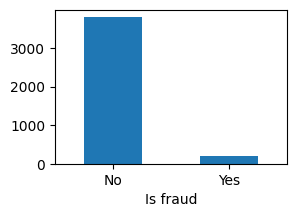

In [10]:
print(f'Percentage of fraud: {len(tf[tf.is_fraud == 1]) / len(tf) * 100 :.02f}%')
plt.figure(figsize=(3,2))
tf.is_fraud.value_counts().rename({0:'No',1:'Yes'}).plot(kind='bar')
plt.xlabel('Is fraud')
plt.xticks(rotation=0)
plt.show()

The ratio of fraud to non-fraud is highly imbalanced.

#### infrastructure_metrics.csv

In [11]:
im.head()

,timestamp,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate,neft_success_rate,imps_success_rate,rtgs_success_rate,avg_transaction_processing_time_ms,auth_success_rate,transaction_volume_per_hour,service_uptime
0,2025-10-20 00:00:00,42.82,36.96,25.62,168.08,0,99.46,99.20,99.71,108.99,99.47,4664,100.0
1,2025-10-20 00:01:00,36.99,33.99,25.53,179.73,2,98.45,98.28,99.29,100.00,98.96,4570,100.0
2,2025-10-20 00:02:00,40.99,33.33,34.22,167.39,0,99.80,99.93,99.81,102.10,98.60,4368,100.0
3,2025-10-20 00:03:00,37.98,32.66,30.48,146.32,3,98.08,99.09,99.18,100.00,99.28,4878,100.0
4,2025-10-20 00:04:00,44.44,33.69,26.14,155.62,1,97.09,99.66,99.36,135.61,99.04,3281,100.0


In [12]:
im.timestamp = pd.to_datetime(im.timestamp)

In [13]:
earliest, latest = im.timestamp.min().date(), im.timestamp.max().date()
print(f'Time span is from {earliest} to {latest}. {(latest - earliest).days + 1} days.')

Time span is from 2025-10-20 to 2025-10-26. 7 days.


In [14]:
print('Shape:', im.shape, '\n')
im.info()

Shape: (10080, 13) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10080 entries, 0 to 10079
Data columns (total 13 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   timestamp                           10080 non-null  datetime64[ns]
 1   cpu_utilization                     10080 non-null  float64       
 2   memory_usage                        10080 non-null  float64       
 3   db_connection_pool_usage            10080 non-null  float64       
 4   network_throughput_mbps             10080 non-null  float64       
 5   application_error_rate              10080 non-null  int64         
 6   neft_success_rate                   10080 non-null  float64       
 7   imps_success_rate                   10080 non-null  float64       
 8   rtgs_success_rate                   10080 non-null  float64       
 9   avg_transaction_processing_time_ms  10080 non-null  float64       
 10  a

In [15]:
print('Missing values: ', im.isnull().sum().sum())

Missing values:  0


All data types are standardized and there are no missing values. It is also worth noting that `application_error_rate` likely actually refers to the number of errors in the past minute, not the rate of errors, since each cell has an integer value, usually from around 0 to 5.

In [16]:
im.duplicated(subset=['timestamp']).sum()

0

In [17]:
print('Unique timestamps:', im.timestamp.nunique())
print('Total rows:', len(im))

Unique timestamps: 10080
Total rows: 10080


There are no duplicates because each row represents a single minute. It includes all minutes during the week of Monday, October 20, 2025 to Sunday, October 26, 2025.

#### incident_reports.csv

In [18]:
ir.head()

,incident_id,timestamp,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate,neft_success_rate,imps_success_rate,rtgs_success_rate,avg_transaction_processing_time_ms,incident_type,severity,is_critical
0,INC000001,2025-10-20 00:00:00,42.82,36.96,25.62,168.08,0,99.46,99.20,99.71,108.99,Normal,Low,0
1,INC000002,2025-10-20 01:00:00,38.23,39.58,33.64,215.29,2,96.62,98.36,99.86,100.11,Normal,Low,0
2,INC000003,2025-10-20 02:00:00,35.37,38.81,22.94,218.44,2,96.49,98.61,99.10,100.00,Normal,Low,0
3,INC000004,2025-10-20 03:00:00,36.81,37.07,39.59,185.52,3,98.56,99.96,99.60,100.00,Normal,Low,0
4,INC000005,2025-10-20 04:00:00,43.25,33.70,39.36,215.06,4,99.96,99.51,99.44,140.75,Normal,Low,0


In [19]:
# Standardize data types
categoricals = ['incident_type', 'severity']
ir[categoricals] = ir[categoricals].astype('category')
ir['timestamp'] = pd.to_datetime(ir['timestamp'])
ir['incident_id'] = ir['incident_id'].astype('string[pyarrow]')

In [20]:
earliest, latest = ir.timestamp.min().date(), ir.timestamp.max().date()
print(f'Time span is from {earliest} to {latest}. {(latest - earliest).days + 1} days.')

Time span is from 2025-10-20 to 2025-10-26. 7 days.


In [21]:
print('Shape:', ir.shape, '\n')
ir.info()

Shape: (168, 14) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 14 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   incident_id                         168 non-null    string        
 1   timestamp                           168 non-null    datetime64[ns]
 2   cpu_utilization                     168 non-null    float64       
 3   memory_usage                        168 non-null    float64       
 4   db_connection_pool_usage            168 non-null    float64       
 5   network_throughput_mbps             168 non-null    float64       
 6   application_error_rate              168 non-null    int64         
 7   neft_success_rate                   168 non-null    float64       
 8   imps_success_rate                   168 non-null    float64       
 9   rtgs_success_rate                   168 non-null    float64       
 10  avg_tra

In [22]:
print('Missing values:', ir.isnull().sum().sum())

Missing values: 0


In [23]:
# Check for duplicates
ir.duplicated(subset=['incident_id']).sum()

0

In [24]:
ir.duplicated(subset=['timestamp']).sum()

0

In [25]:
(ir.timestamp.sort_values() == ir.timestamp).sum()

168

There are no duplicates with either `incident_id` or `timestamp`. The timestamps represent each hour from 12 AM October 20, 2025 to 11 PM October 26, 2025 in order.

#### application_logs.csv

In [26]:
al.head()

,timestamp,log_level,log_message
0,2025-10-20 00:00:00,INFO,INFO: Transaction processed successfully. ID: ...
1,2025-10-20 00:01:00,ERROR,ERROR: NEFT transaction failed. Transaction ID...
2,2025-10-20 00:01:00,ERROR,ERROR: Database connection pool exhausted. Con...
3,2025-10-20 00:03:00,ERROR,ERROR: IMPS transaction failed. Transaction ID...
4,2025-10-20 00:03:00,WARNING,WARNING: Memory usage approaching threshold on...


In [27]:
# Standardize data types
al['timestamp'] = pd.to_datetime(al['timestamp'])
al['log_level'] = al['log_level'].astype('category')
al['log_message'] = al['log_message'].astype('string[pyarrow]')

In [28]:
print('Shape:', al.shape, '\n')
al.info()

Shape: (5000, 3) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   timestamp    5000 non-null   datetime64[ns]
 1   log_level    5000 non-null   category      
 2   log_message  5000 non-null   string        
dtypes: category(1), datetime64[ns](1), string(1)
memory usage: 368.4 KB


In [29]:
print('Missing values:', al.isnull().sum().sum())

Missing values: 0


All data types are standardized and there are no missing values.

In [30]:
# Check for duplicates
print('Number of duplicate logs:', al.duplicated().sum())
print('All duplicates shown:')
al[al.duplicated(keep=False)]

Number of duplicate logs: 9
All duplicates shown:


,timestamp,log_level,log_message
149,2025-10-20 04:39:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...
151,2025-10-20 04:39:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...
306,2025-10-20 10:03:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...
307,2025-10-20 10:03:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...
1590,2025-10-22 05:06:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...
1591,2025-10-22 05:06:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...
1710,2025-10-22 09:11:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...
1712,2025-10-22 09:11:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...
1734,2025-10-22 09:56:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...
1735,2025-10-22 09:56:00,ERROR,ERROR: API rate limit exceeded for endpoint /a...


In [31]:
al.drop_duplicates(inplace=True)

9 rows had exact duplicates, so they were dropped.

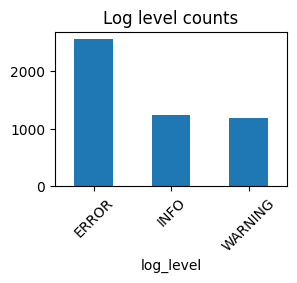

In [32]:
plt.figure(figsize=(3,2))
al.log_level.value_counts().plot(kind='bar')
plt.xticks(rotation=45)
plt.title('Log level counts')
plt.show()

#### credit_applications.csv

In [33]:
ca.head()

,application_id,customer_id,application_date,loan_type,loan_amount,loan_term_months,employment_type,existing_loans,debt_to_income_ratio,credit_inquiries_6m,payment_history_months,approval_status,is_default
0,APP000001,CUST000001,2024-06-28,Business_Loan,3830111.33,60,Salaried,1,0.224,1,12,Rejected,NaN
1,APP000002,CUST000002,2025-02-09,Personal_Loan,110732.55,36,Salaried,3,0.326,0,33,Approved,0.0
2,APP000003,CUST000003,2024-05-08,Personal_Loan,290880.32,60,Student,0,0.324,2,18,Rejected,NaN
3,APP000004,CUST000004,2024-06-21,Home_Loan,1735421.12,180,Salaried,3,0.382,0,4,Approved,0.0
4,APP000005,CUST000005,2024-08-21,Personal_Loan,81309.52,36,Salaried,0,0.467,2,55,Rejected,NaN


In [34]:
print('Unique values per column:')
for col, size in ca.nunique().sort_values().items():
    print(f'{col:<18s}', size)
    uniques = [str(unique) for unique in ca[col].unique()]
    if len(uniques) <= 11:
        print('    (', ', '.join(uniques), ')', sep='')

Unique values per column:
approval_status    2
    (Rejected, Approved)
is_default         2
    (nan, 0.0, 1.0)
loan_type          5
    (Business_Loan, Personal_Loan, Home_Loan, Credit_Card, Auto_Loan)
employment_type    5
    (Salaried, Student, Self_Employed, Retired, Business_Owner)
existing_loans     5
    (1, 3, 0, 2, 4)
loan_term_months   11
    (60, 36, 180, 12, 120, 24, 48, 0, 300, 240, 84)
credit_inquiries_6m 11
    (1, 0, 2, 3, 5, 4, 6, 7, 10, 11, 8)
payment_history_months 114
debt_to_income_ratio 699
application_date   728
application_id     4000
customer_id        4000
loan_amount        4000


This table shows which columns are categorical columns: `approval_status`, `is_default`, `loan_type`, and `employment_type`.

In [35]:
categorical_cols = ['approval_status', 'loan_type', 'employment_type']
ca[categorical_cols] = ca[categorical_cols].astype('category')

string_cols = ['application_id', 'customer_id']
ca[string_cols] = ca[string_cols].astype('string[pyarrow]')

ca['application_date'] = pd.to_datetime(ca['application_date'])

In [36]:
print('Shape:', ca.shape, '\n')
ca.info()

Shape: (4000, 13) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   application_id          4000 non-null   string        
 1   customer_id             4000 non-null   string        
 2   application_date        4000 non-null   datetime64[ns]
 3   loan_type               4000 non-null   category      
 4   loan_amount             4000 non-null   float64       
 5   loan_term_months        4000 non-null   int64         
 6   employment_type         4000 non-null   category      
 7   existing_loans          4000 non-null   int64         
 8   debt_to_income_ratio    4000 non-null   float64       
 9   credit_inquiries_6m     4000 non-null   int64         
 10  payment_history_months  4000 non-null   int64         
 11  approval_status         4000 non-null   category      
 12  is_default              2813

In [37]:
print('Missing values:')
print(ca.isnull().sum())

Missing values:
application_id               0
customer_id                  0
application_date             0
loan_type                    0
loan_amount                  0
loan_term_months             0
employment_type              0
existing_loans               0
debt_to_income_ratio         0
credit_inquiries_6m          0
payment_history_months       0
approval_status              0
is_default                1187
dtype: int64


In [38]:
ca['is_default'] = ca['is_default'].map({0: 'No', 1: 'Yes'}).fillna('Missing')

display(pd.crosstab(
    ca.approval_status, 
    ca.is_default
))

is_default,Missing,No,Yes
approval_status,,,
Approved,0,2194,619
Rejected,1187,0,0


`is_default` has 1187 missing cells, but these are all from applications that were rejected as is seen in the crosstab, because those can't be in default. 

In [39]:
ca['is_default'] = ca['is_default'].replace('Missing', 'N/A')
ca['is_default'] = ca['is_default'].astype('category')

I have replaced all missing values with 'N/A' to signify that defaulting can't apply to applications that were rejected.

In [40]:
print('Missing values:', ca.isnull().sum().sum())

Missing values: 0


In [41]:
ca.duplicated(subset=['application_id']).sum()

0

In [42]:
ca.duplicated(subset=['customer_id']).sum()

0

There are no duplicated applications nor customers. Each customer in this table made exactly one application.

#### customer_demographics.csv

In [43]:
cd.head()

,customer_id,age,gender,income_level,annual_income,city,account_age_months,credit_score
0,CUST000001,52,M,Medium,53786.925641,Kolkata,13,771
1,CUST000002,42,M,Low,26998.570675,Chennai,41,651
2,CUST000003,54,M,High,118010.875701,Mumbai,62,656
3,CUST000004,67,M,Medium,55340.075245,Delhi,19,701
4,CUST000005,41,M,Medium,40057.029132,Kolkata,82,769


In [44]:
print('Unique values per column:')
for col, size in cd.nunique().sort_values().items():
    print(f'{col:<18s}', size)
    uniques = [str(unique) for unique in cd[col].unique()]
    if len(uniques) <= 8:
        print('    (', ', '.join(uniques), ')', sep='')

Unique values per column:
gender             3
    (M, F, Other)
income_level       4
    (Medium, Low, High, Very High)
city               8
    (Kolkata, Chennai, Mumbai, Delhi, Pune, Ahmedabad, Bangalore, Hyderabad)
age                68
account_age_months 188
credit_score       363
customer_id        5000
annual_income      5000


This table shows which columns are category columns: `gender`, `income_level`, `city`.

In [45]:
categorical_cols = ['gender', 'income_level', 'city']
cd[categorical_cols] = cd[categorical_cols].astype('category')
cd['customer_id'] = cd['customer_id'].astype('string[pyarrow]')

In [46]:
print('Shape:', cd.shape, '\n')
cd.info()

Shape: (5000, 8) 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   customer_id         5000 non-null   string  
 1   age                 5000 non-null   int64   
 2   gender              5000 non-null   category
 3   income_level        5000 non-null   category
 4   annual_income       5000 non-null   float64 
 5   city                5000 non-null   category
 6   account_age_months  5000 non-null   int64   
 7   credit_score        5000 non-null   int64   
dtypes: category(3), float64(1), int64(3), string(1)
memory usage: 259.6 KB


In [47]:
print('Missing values:', cd.isnull().sum().sum())

Missing values: 0


In [48]:
cd.duplicated(subset=['customer_id']).sum()

0

None of the customers are duplicated.

### Explore distributions of key business KPIs, such as success rates and processing times

In [49]:
kpis = ['neft_success_rate', 'imps_success_rate', 'rtgs_success_rate', 
    'avg_transaction_processing_time_ms', 'auth_success_rate', 
    'transaction_volume_per_hour']

display(im[kpis].describe().round(2) .loc[:'std'])
display(im[kpis].describe().round(2) .loc['min':])

,neft_success_rate,imps_success_rate,rtgs_success_rate,avg_transaction_processing_time_ms,auth_success_rate,transaction_volume_per_hour
count,10080.00,10080.00,10080.00,10080.00,10080.00,10080.00
mean,98.00,99.01,99.50,199.78,98.96,4906.66
std,1.15,0.58,0.29,126.29,0.39,1415.43


,neft_success_rate,imps_success_rate,rtgs_success_rate,avg_transaction_processing_time_ms,auth_success_rate,transaction_volume_per_hour
min,96.00,98.00,99.00,100.00,96.51,3000.0
25%,97.02,98.51,99.26,100.00,98.73,3805.0
50%,97.98,99.02,99.50,130.91,98.99,4505.0
75%,98.98,99.51,99.75,350.76,99.24,6137.5
max,100.00,100.00,100.00,477.97,99.50,7997.0


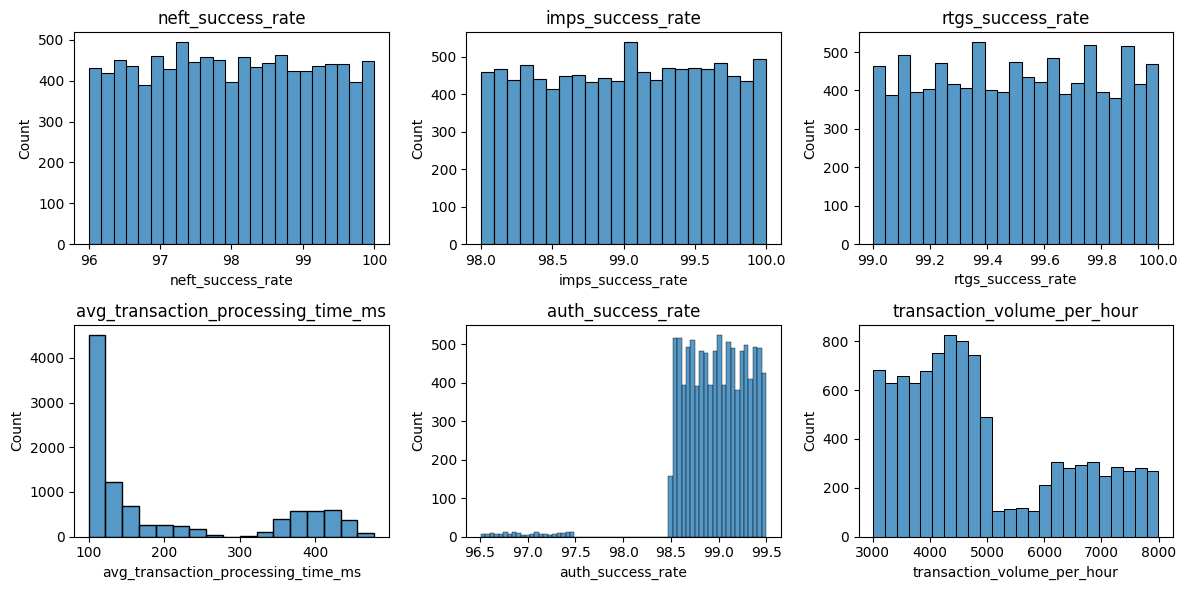

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))

for ax, col in zip(axes.ravel(), kpis):
    sns.histplot(im[col], ax=ax)
    ax.set_title(col)
fig.tight_layout()

For the success rates, they are evenly distributed each around a high range. 

Average processing times have two modes, which later plots show that the first mode is from non-business hours, and the second mode is from business hours. These also explain the two modes in the transaction volume plot.

Auth success rate also shows two modes, with the first mode likely being from times where CPU usage is limited and the second mode being from all the other times.

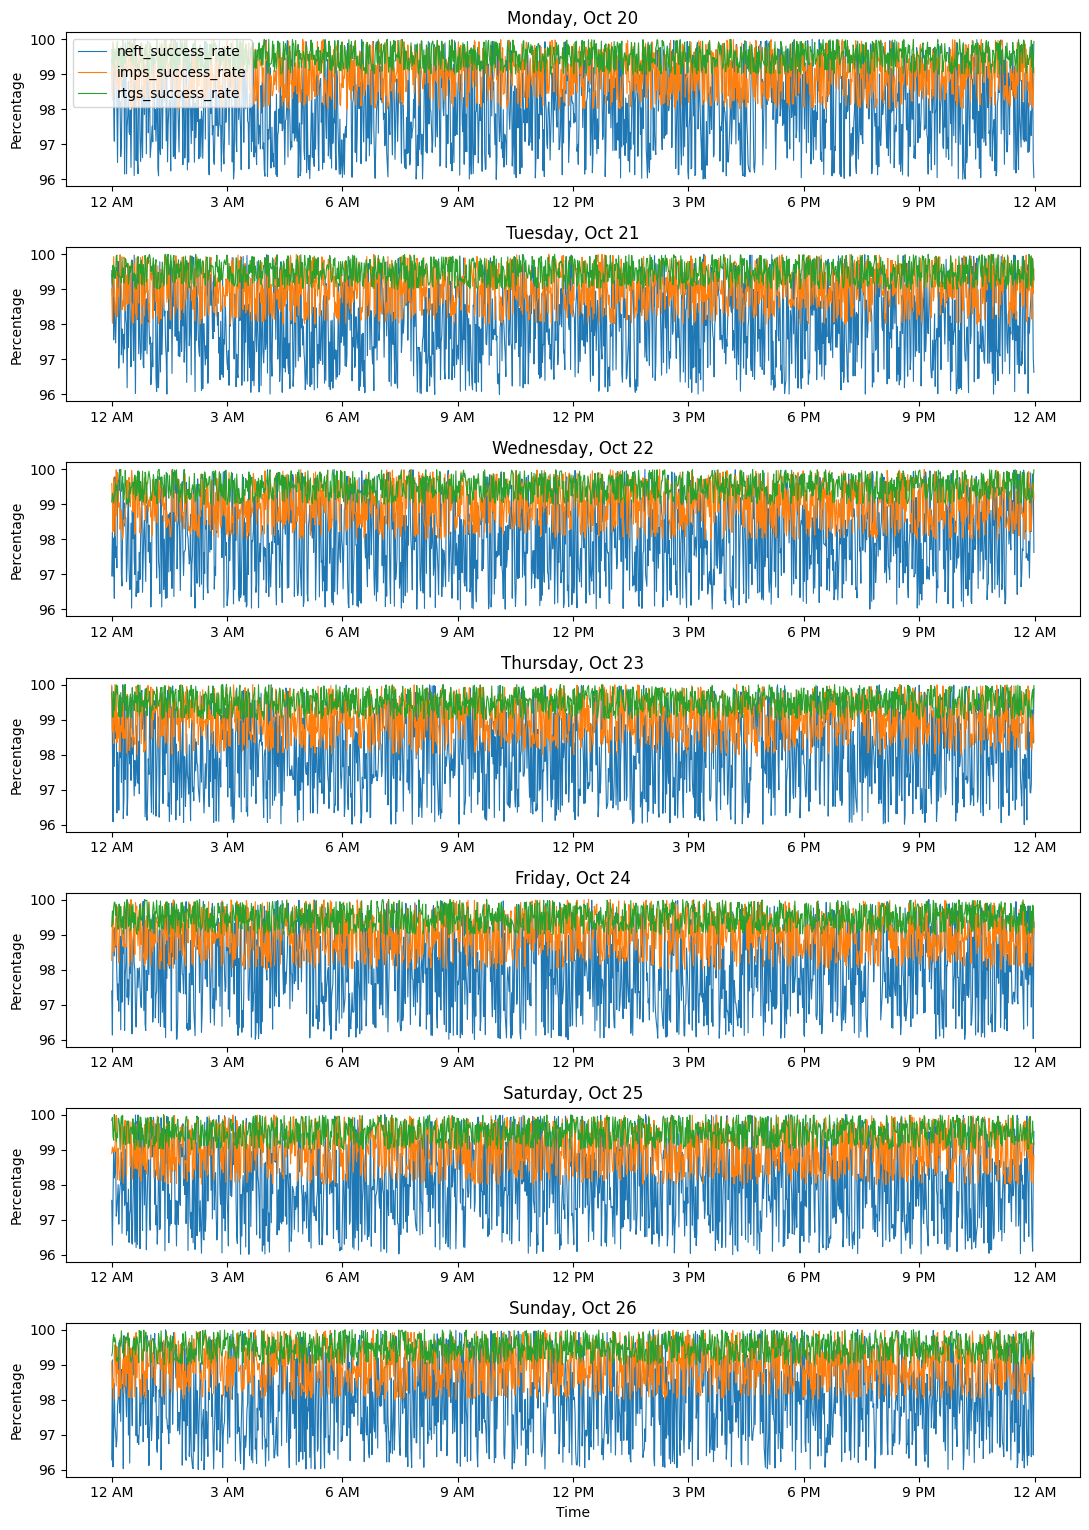

In [51]:
import matplotlib.dates as mdates

metrics = ['neft_success_rate', 'imps_success_rate', 'rtgs_success_rate']

days = sorted(im['timestamp'].dt.date.unique())

fig, axes = plt.subplots(len(days), 1, figsize=(11, 2.2 * len(days)))

for ax, day in zip(axes, days):
    day_df = im[im['timestamp'].dt.date == day]

    for col in metrics:
        ax.plot(day_df['timestamp'], day_df[col], label=col, linewidth=0.8)

    ax.set_ylabel('Percentage')
    ax.set_title(day.strftime('%A, %b %-d'))
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%-I %p'))

axes[0].legend(loc='upper left'); axes[-1].set_xlabel('Time')
fig.tight_layout()

These plots show that success rates seem to always oscillate within the same range throughout every day of the week without being affected by transaction volume or server usage metrics, which aligns with the histograms.

### Analyze infrastructure metrics, including CPU utilization, memory usage, and error rates

In [52]:
metrics = ['cpu_utilization', 'memory_usage', 'db_connection_pool_usage', 'network_throughput_mbps',
         'application_error_rate', 'service_uptime']

display(im[metrics].describe().round(2).loc[:'std'])
display(im[metrics].describe().round(2).loc['min':])

,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate,service_uptime
count,10080.00,10080.00,10080.00,10080.00,10080.00,10080.00
mean,49.12,44.19,39.31,245.22,2.00,100.00
std,13.36,11.85,11.83,71.25,1.42,0.06


,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate,service_uptime
min,32.90,30.86,19.71,140.05,0.0,94.0
25%,39.07,35.39,30.11,189.54,1.0,100.0
50%,42.98,37.79,36.88,224.97,2.0,100.0
75%,65.44,60.09,48.09,306.37,3.0,100.0
max,77.52,68.16,68.06,415.70,10.0,100.0


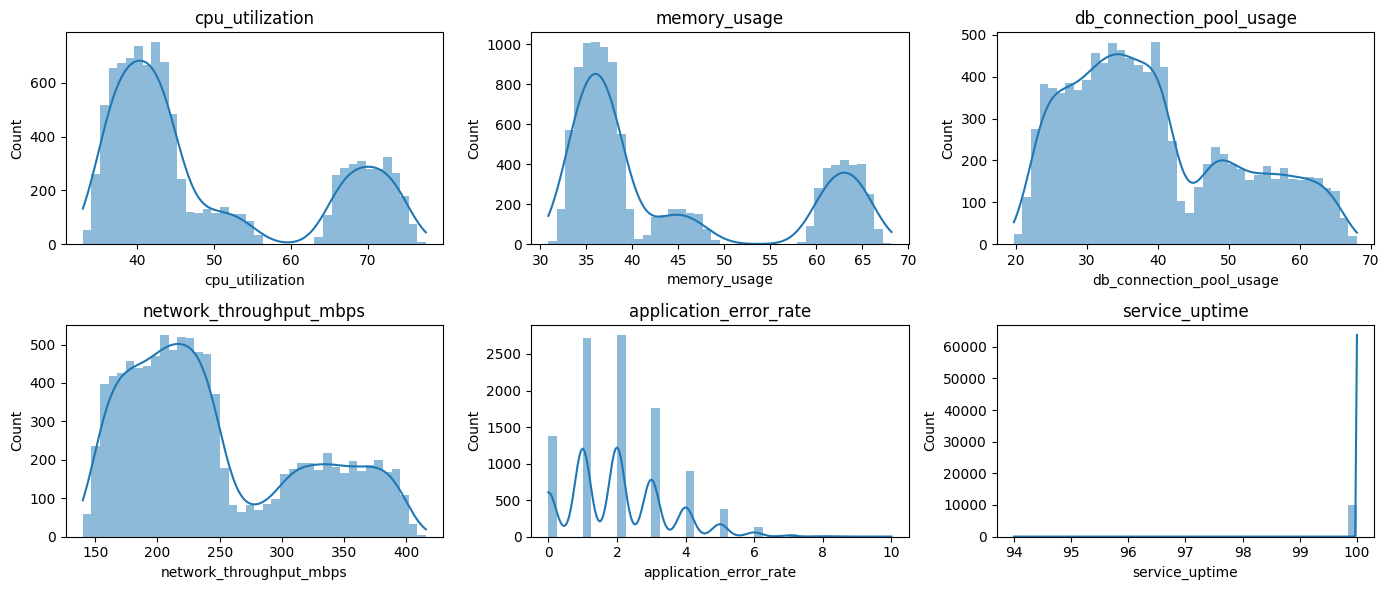

In [53]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6))

for ax, col in zip(axes.ravel(), metrics):
    sns.histplot(im[col], bins=40, kde=True, ax=ax, linewidth=0)
    ax.set_title(col)
    
fig.tight_layout()

`cpu_utilization`, `memory_usage`, `db_connection_pool_usage`, and `network_throughput_mbps` all have similar shapes which is due to the difference in volume during business hours and non-business hours, as seen in later plots.

`application_error_rate` mostly ranges between 0 and 6 but can go up to 10. They don't have the same shape as the first four, so this may suggest that they don't correlate with them.

`service_uptime` is 100 in all rows except for 1.

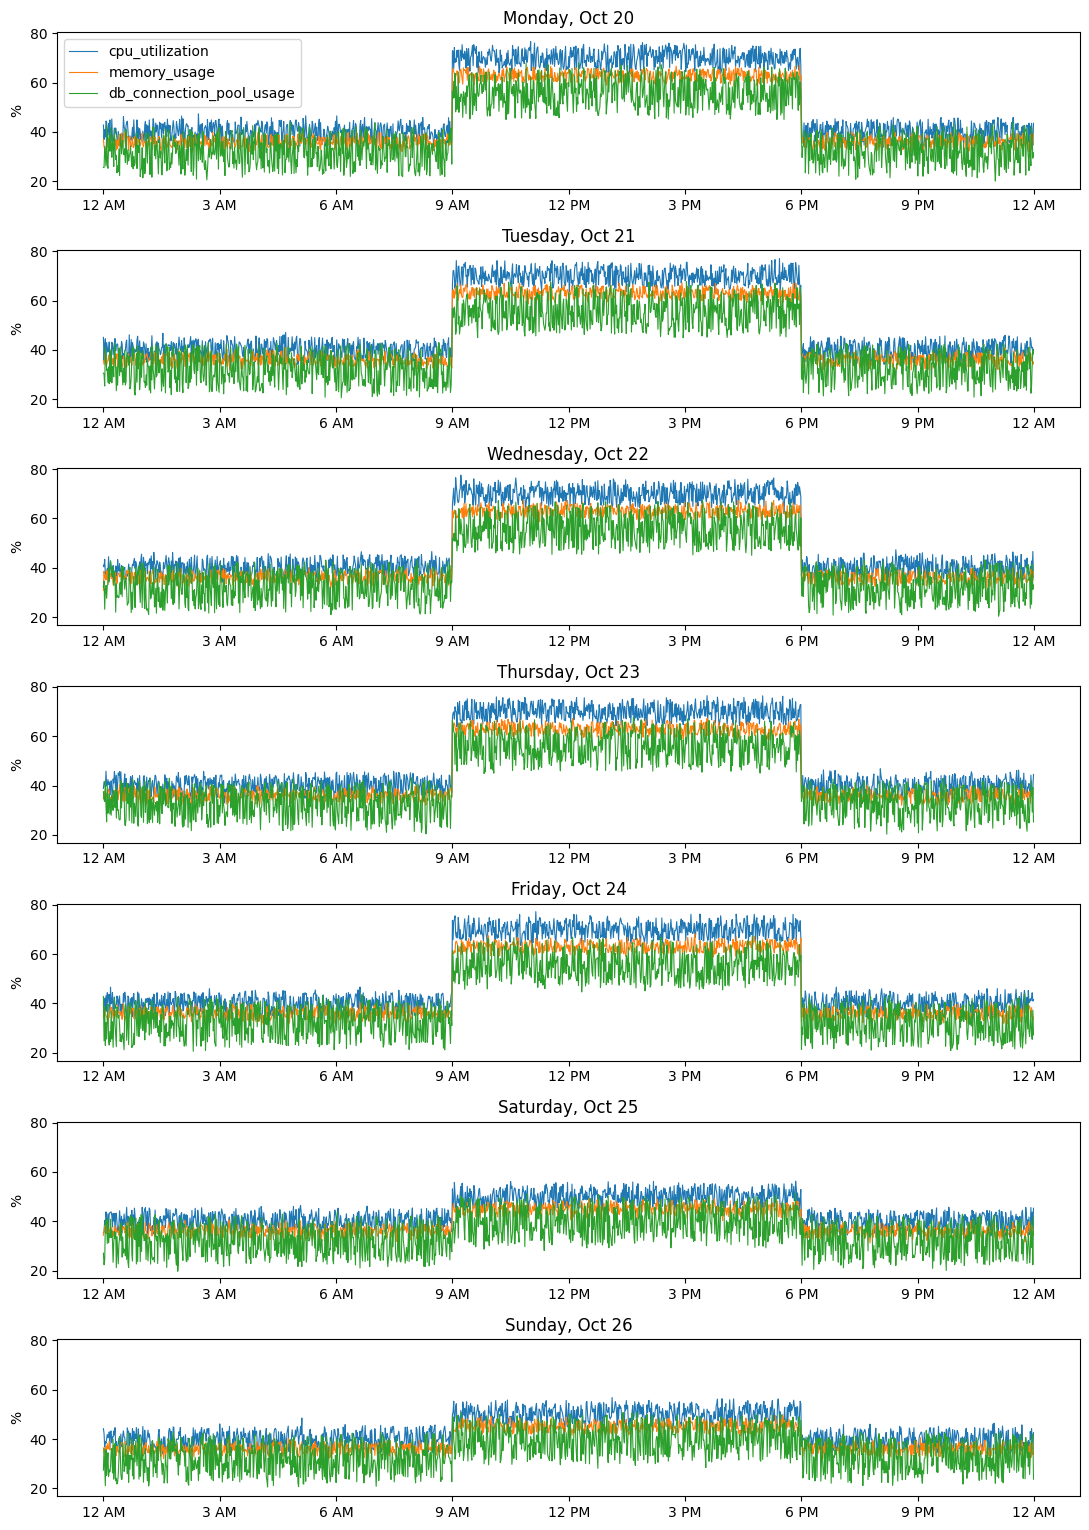

In [54]:
metrics = ['cpu_utilization', 'memory_usage', 'db_connection_pool_usage']
days = sorted(im['timestamp'].dt.date.unique())

fig, axes = plt.subplots(len(days), 1, figsize=(11, 2.2 * len(days)), sharey=True)

for ax, day in zip(axes, days):
    day_df = im[im['timestamp'].dt.date == day]

    for col in metrics:
        ax.plot(day_df['timestamp'], day_df[col], label=col, linewidth=0.8)

    ax.set_ylabel('%')
    ax.set_title(day.strftime('%A, %b %-d'))
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%-I %p'))
    
axes[0].legend(loc='upper left')
fig.tight_layout()

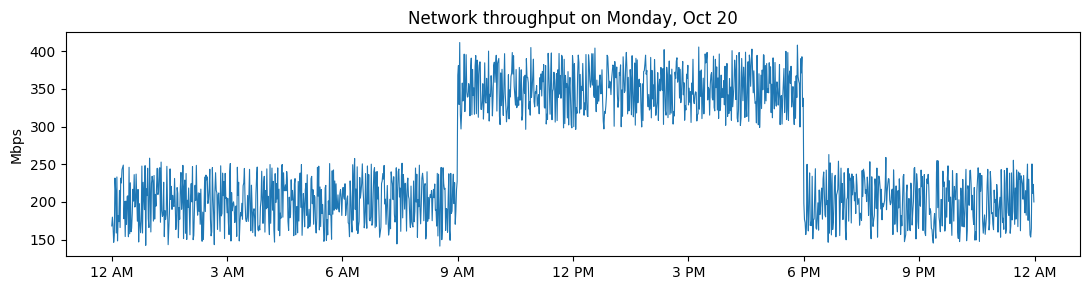

In [55]:
day = im[im.timestamp.dt.date == im.timestamp.dt.date.min()]
day_title = 'Monday, Oct 20'

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(day.timestamp, day.network_throughput_mbps, lw=0.8)
ax.set_ylabel('Mbps')
ax.set_title(f'Network throughput on {day_title}')
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%-I %p'))

fig.tight_layout()

Similarly, network throughput has the same spike from 9am to 6pm.

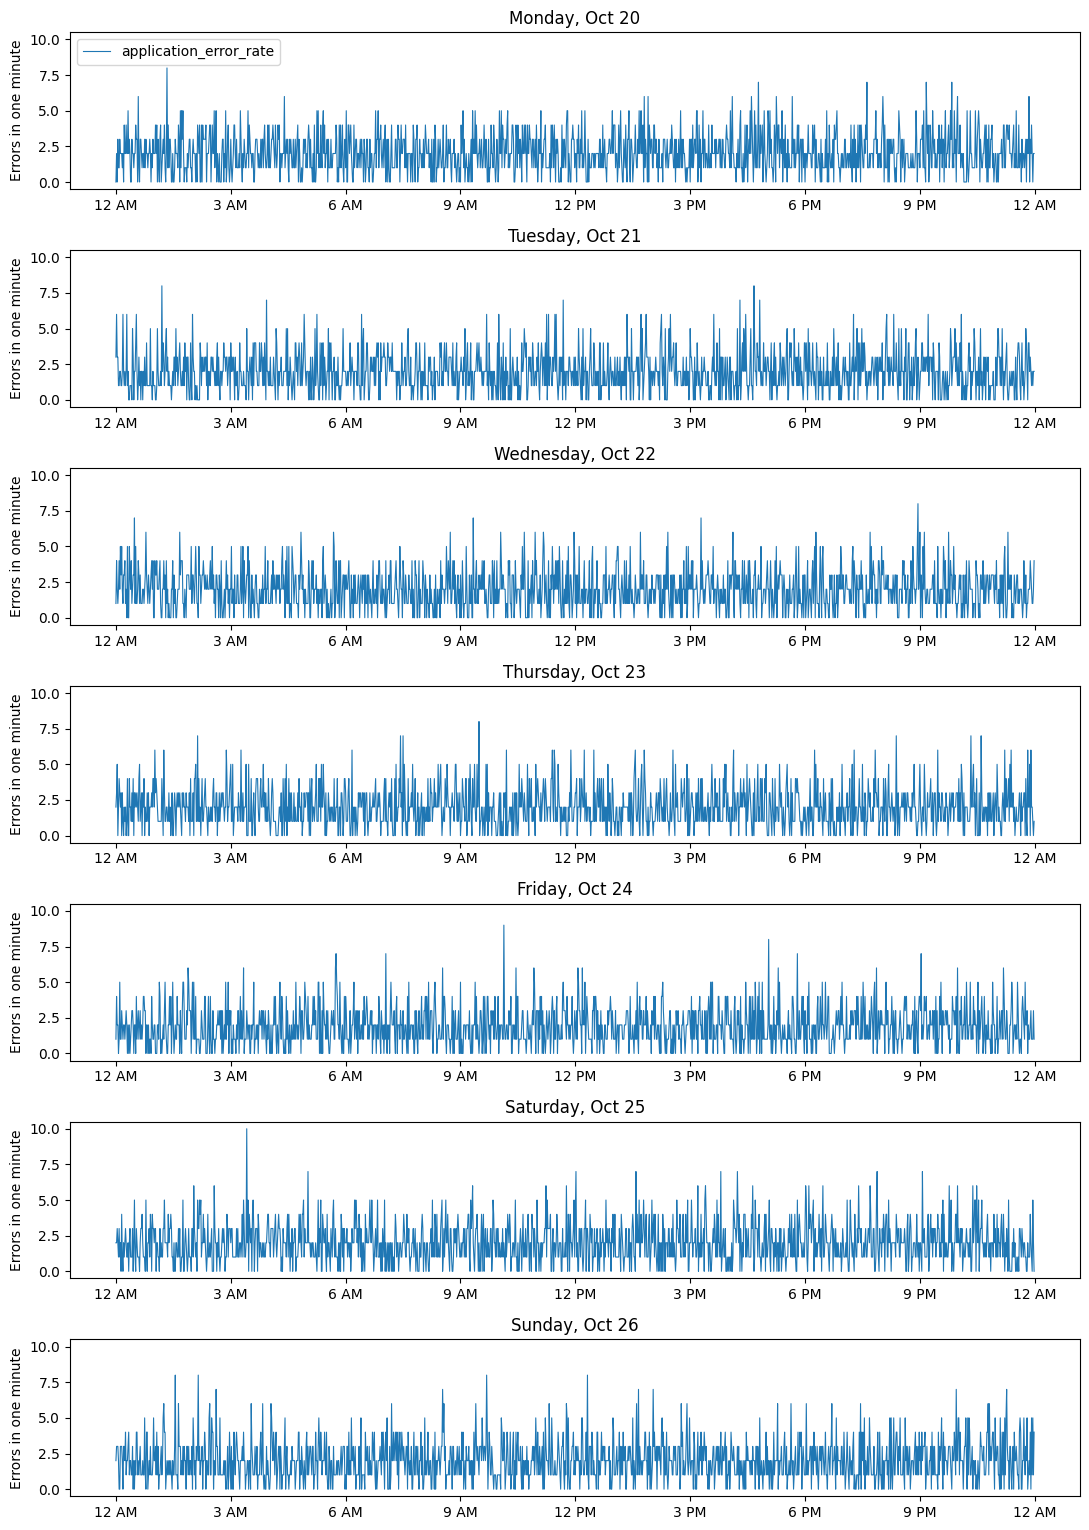

In [56]:
metrics = ['application_error_rate']
days = sorted(im['timestamp'].dt.date.unique())

fig, axes = plt.subplots(len(days), 1, figsize=(11, 2.2 * len(days)), sharey=True)

for ax, day in zip(axes, days):
    day_df = im[im['timestamp'].dt.date == day]

    for col in metrics:
        ax.plot(day_df['timestamp'], day_df[col], label=col, linewidth=0.8)
        
    ax.set_ylabel('Errors in one minute')
    ax.set_title(day.strftime('%A, %b %-d'))
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%-I %p'))

axes[0].legend(loc='upper left')
fig.tight_layout()

Error rates do not seem to follow any pattern. They steadily oscillate between around 0 and 5 with occasional spikes, similar to success rates.

### Correlate transaction performance with infrastructure load

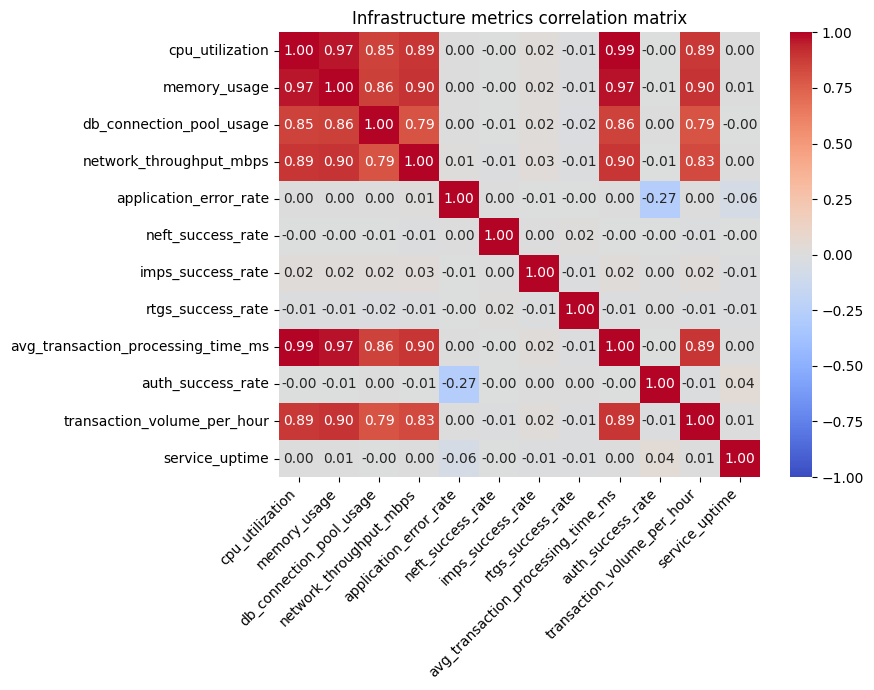

In [57]:
num_cols = [c for c in im.select_dtypes('number').columns if c not in ('hour',)]
corr = im[num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1)
plt.title('Infrastructure metrics correlation matrix')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

This heatmap shows strong correlations between `cpu_utilization`, `memory_usage`, `db_connection_pool_usage`, `network_throughput_mbps`, `avg_transaction_processing_time_ms` and `transaction_volume_per_hour`, signifying that all of these metrics are interconnected. The likely explanation is that as transaction volume increases during 9am to 6pm, server metrics go up, which slow down processing times. 
       
It shows a slight negative correlation (-0.27) between `auth_success_rate` and `application_error_rate`.

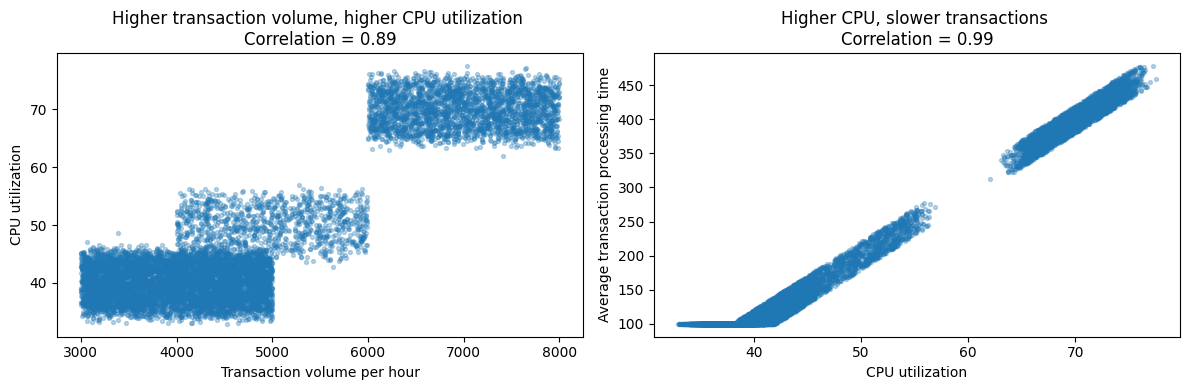

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Transaction volume vs CPU utilization
axes[0].scatter(im.transaction_volume_per_hour, im.cpu_utilization, s=8, alpha=0.3)
axes[0].set_xlabel('Transaction volume per hour')
axes[0].set_ylabel('CPU utilization')
corr1 = im['transaction_volume_per_hour'].corr(im['cpu_utilization'])
axes[0].set_title(
    f'Higher transaction volume, higher CPU utilization \n' 
    f'Correlation = {corr1:.2f}'
)

# CPU utilization vs transaction speed
axes[1].scatter(im.cpu_utilization, im.avg_transaction_processing_time_ms, s=8, alpha=0.3)
axes[1].set_xlabel('CPU utilization')
axes[1].set_ylabel('Average transaction processing time')
corr2 = im['cpu_utilization'].corr(im['avg_transaction_processing_time_ms'])
axes[1].set_title(
    f'Higher CPU, slower transactions \n' 
    f'Correlation = {corr2:.2f}'
)

fig.tight_layout()

The first plot shows that as the rate of transactions coming in increases, the CPU utilization increases with it. The rectangle in the top-right corresponds to the spike in transactions seen during 9 am to 6 pm on business days.

The second plot shows that as CPU utilization goes up, the average time for a transaction to process goes up at the same rate. The disjointed line on the top-right corresponds to the same spike in transactions.

These two plots show that as the infrastructure is loaded with more transactions to process, the CPU utilization goes up (along with memory usage, DB connection pool usage, and network throughput), and as a result, the speed of each transaction slows down.

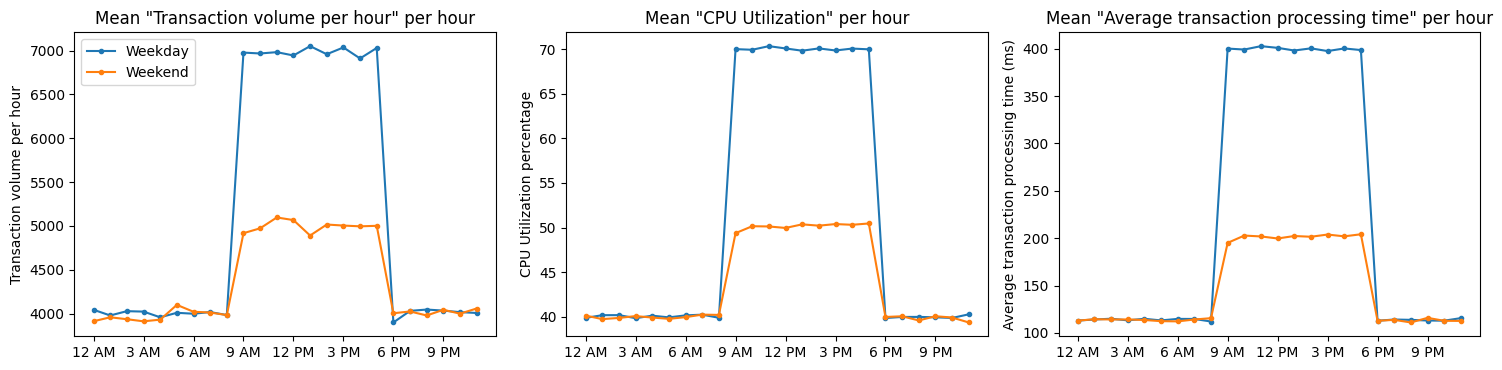

In [59]:
im['hour'] = im.timestamp.dt.hour
im['weekend'] = im.timestamp.dt.dayofweek >= 5

prof = im.groupby(['weekend', 'hour'])[['transaction_volume_per_hour', 'cpu_utilization', 'avg_transaction_processing_time_ms']].mean()

title_and_ylabel = [
    ['Mean "Transaction volume per hour" per hour', 'Transaction volume per hour'],
    ['Mean "CPU Utilization" per hour', 'CPU Utilization percentage'],
    ['Mean "Average transaction processing time" per hour', 'Average transaction processing time (ms)']
]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, (title, ylabel) in zip(axes, prof.columns, title_and_ylabel):
    for is_weekend, lab in [(False, 'Weekday'), (True, 'Weekend')]:
        ax.plot(prof.loc[is_weekend, col].index, prof.loc[is_weekend, col].values, marker='o', ms=3, label=lab)
        
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xticklabels([pd.Timestamp(2000, 1, 1, h).strftime('%-I %p') for h in range(0, 24, 3)])

axes[0].legend(loc='upper left')
fig.tight_layout()

These plots show the relationship more clearly. For each hour of the day, it takes the average of these three metrics (`transaction_volume_per_hour`, `cpu_utilization`, `avg_transaction_processing_time_ms`) across all 7 days in the dataset and plots the average as a dot. It does this for both weekdays and weekends. It shows that when transaction volume goes up, CPU utilization and average transaction processing times also go up, significantly more during weekdays than during weekends.

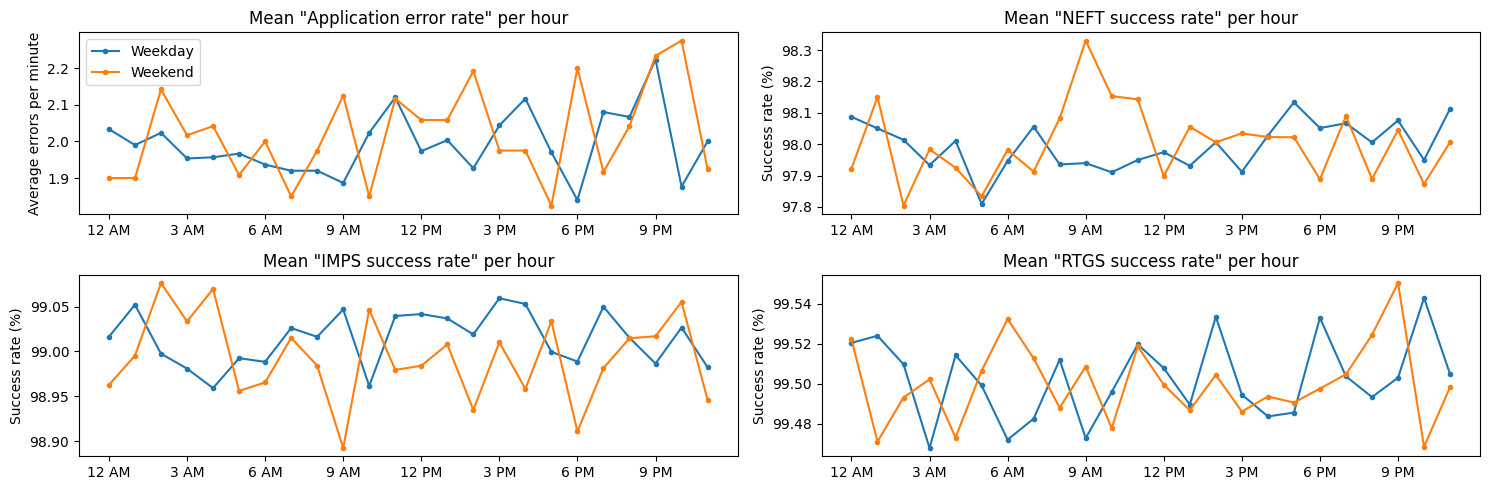

In [60]:
im['hour'] = im.timestamp.dt.hour
im['weekend'] = im.timestamp.dt.dayofweek >= 5

prof = im.groupby(['weekend', 'hour'])[['application_error_rate', 'neft_success_rate', 'imps_success_rate', 'rtgs_success_rate',]].mean()

title_and_ylabel = [
    ['Mean "Application error rate" per hour', 'Average errors per minute'],
    ['Mean "NEFT success rate" per hour', 'Success rate (%)'],
    ['Mean "IMPS success rate" per hour', 'Success rate (%)'],
    ['Mean "RTGS success rate" per hour', 'Success rate (%)'],
]

fig, axes = plt.subplots(2, 2, figsize=(15, 5))
for ax, col, (title, ylabel) in zip(axes.ravel(), prof.columns, title_and_ylabel):
    for is_weekend, lab in [(False, 'Weekday'), (True, 'Weekend')]:
        ax.plot(prof.loc[is_weekend, col].index, prof.loc[is_weekend, col].values, marker='o', ms=3, label=lab)
        
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xticklabels([pd.Timestamp(2000, 1, 1, h).strftime('%-I %p') for h in range(0, 24, 3)])

axes[0, 0].legend(loc='upper left')
fig.tight_layout()

These plots show that these success rates do not follow the same pattern as CPU Utilization, transaction volume, and average processing times. They perform consistently within a narrow range throughout every hour of the day for all weekdays and weekends.

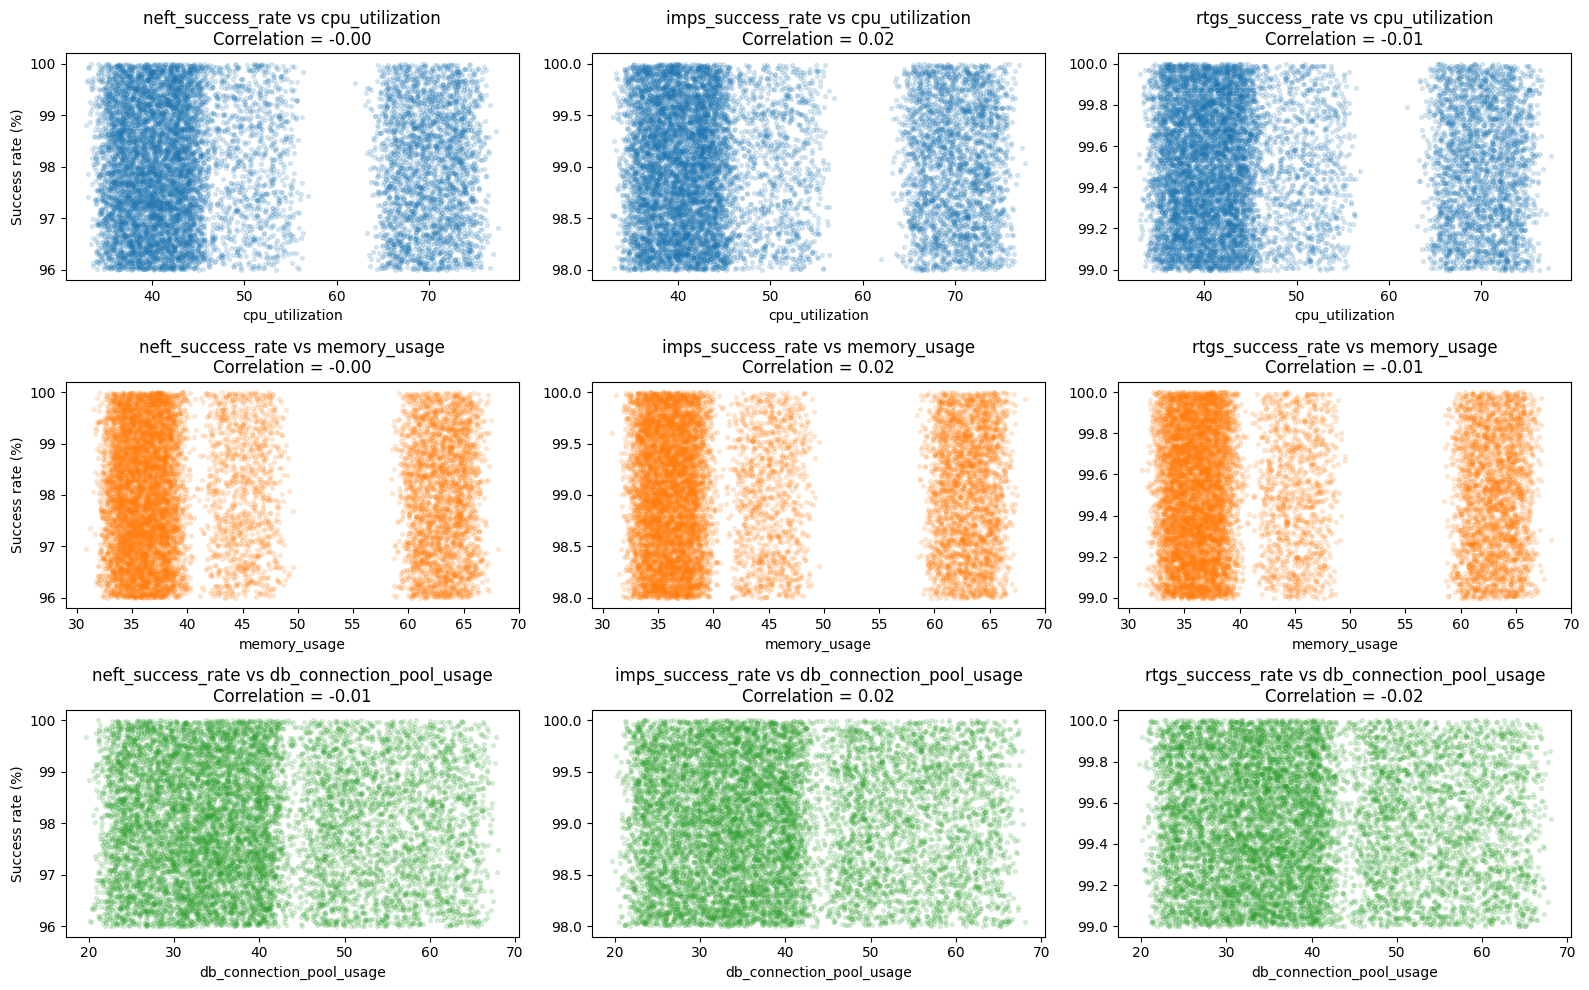

In [61]:
success_rate_cols = ['neft_success_rate', 'imps_success_rate', 'rtgs_success_rate']
server_cols = ['cpu_utilization', 'memory_usage', 'db_connection_pool_usage']

fig, axes = plt.subplots(3, 3, figsize=(16, 10))
for row, (server_col, color) in enumerate(zip(server_cols, ['C0', 'C1', 'C2'])):
    for col, success_rate_col in enumerate(success_rate_cols):
        ax = axes[row, col]
        correlation = im[server_col].corr(im[success_rate_col])
        ax.scatter(im[server_col], im[success_rate_col], alpha=0.15, s=8, color=color)

        ax.set_title(f'{success_rate_col} vs {server_col}\nCorrelation = {correlation:.2f}')
        ax.set_xlabel(server_col)
        if col == 0:
            ax.set_ylabel('Success rate (%)')
            
fig.tight_layout()

These plots directly show that CPU utilization, memory usage, and DB connection pool have no correlation with success rates, as is confirmed by the heatmap from earlier. For each of these, the server is being used more as the x-axis values increase from left to right, yet the success rates stay within their same ranges, showing that increased infrastructure load does not affect these success rates.

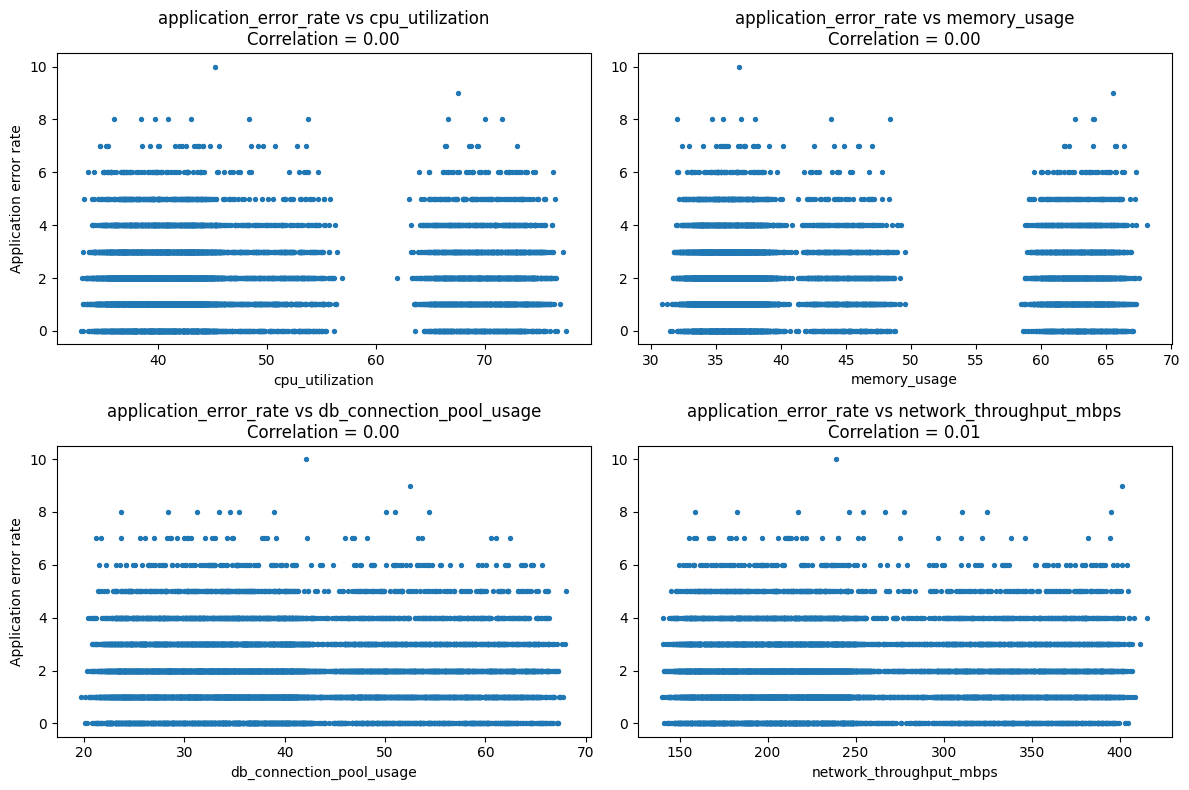

In [62]:
server_cols = ['cpu_utilization', 'memory_usage', 'db_connection_pool_usage', 'network_throughput_mbps']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, (ax, col) in enumerate(zip(axes.ravel(), server_cols)):
    correlation = im[col].corr(im.application_error_rate)
    ax.scatter(im[col], im.application_error_rate, s=8)

    ax.set_title(f'application_error_rate vs {col}\nCorrelation = {correlation:.2f}')
    ax.set_xlabel(col)
    if i % 2 == 0:
        ax.set_ylabel('Application error rate')
        
fig.tight_layout()

These plots show the same thing for application error rates. As the server metrics increase from left to right, the error rates stay mostly consistent, so they are not affected by higher load on the server infrastructure.

### Visualize patterns to identify system bottlenecks and anomalies

In [63]:
ir.head()

,incident_id,timestamp,cpu_utilization,memory_usage,db_connection_pool_usage,network_throughput_mbps,application_error_rate,neft_success_rate,imps_success_rate,rtgs_success_rate,avg_transaction_processing_time_ms,incident_type,severity,is_critical
0,INC000001,2025-10-20 00:00:00,42.82,36.96,25.62,168.08,0,99.46,99.20,99.71,108.99,Normal,Low,0
1,INC000002,2025-10-20 01:00:00,38.23,39.58,33.64,215.29,2,96.62,98.36,99.86,100.11,Normal,Low,0
2,INC000003,2025-10-20 02:00:00,35.37,38.81,22.94,218.44,2,96.49,98.61,99.10,100.00,Normal,Low,0
3,INC000004,2025-10-20 03:00:00,36.81,37.07,39.59,185.52,3,98.56,99.96,99.60,100.00,Normal,Low,0
4,INC000005,2025-10-20 04:00:00,43.25,33.70,39.36,215.06,4,99.96,99.51,99.44,140.75,Normal,Low,0


This table shares most of its columns with infrastructure_metrics, but the timestamps are per hour instead of per minute.

In [64]:
display(pd.crosstab(ir.incident_type, ir.is_critical))
print(f'\nCritical percentage: {ir.is_critical.mean() * 100 :.1f}%')

is_critical,0,1
incident_type,,
Normal,139,0
Resource_Exhaustion,0,26
Resource_Warning,3,0



Critical percentage: 15.5%


This shows that all critical incidents are of type "Resource_Exhaustion", and they comprise 15.5% of the data.

In [65]:
cols = ['cpu_utilization', 'memory_usage', 'db_connection_pool_usage', 'application_error_rate',
        'neft_success_rate', 'imps_success_rate',
       'rtgs_success_rate', 'avg_transaction_processing_time_ms']

display(
    ir.groupby('is_critical')[cols]
        .agg(lambda series: f'({series.min() :.1f}, {series.max() :.1f})')
        .rename(index={0: 'normal (min, max)', 1: 'critical (min, max)'})
        .T
)

is_critical,"normal (min, max)","critical (min, max)"
cpu_utilization,"(34.0, 76.4)","(85.4, 94.8)"
memory_usage,"(32.2, 66.3)","(80.8, 89.9)"
db_connection_pool_usage,"(20.1, 66.6)","(85.1, 93.8)"
application_error_rate,"(0.0, 6.0)","(10.0, 19.0)"
neft_success_rate,"(96.0, 100.0)","(85.1, 89.8)"
imps_success_rate,"(98.0, 100.0)","(98.2, 100.0)"
rtgs_success_rate,"(99.0, 100.0)","(99.0, 100.0)"
avg_transaction_processing_time_ms,"(100.0, 469.6)","(100.0, 436.5)"


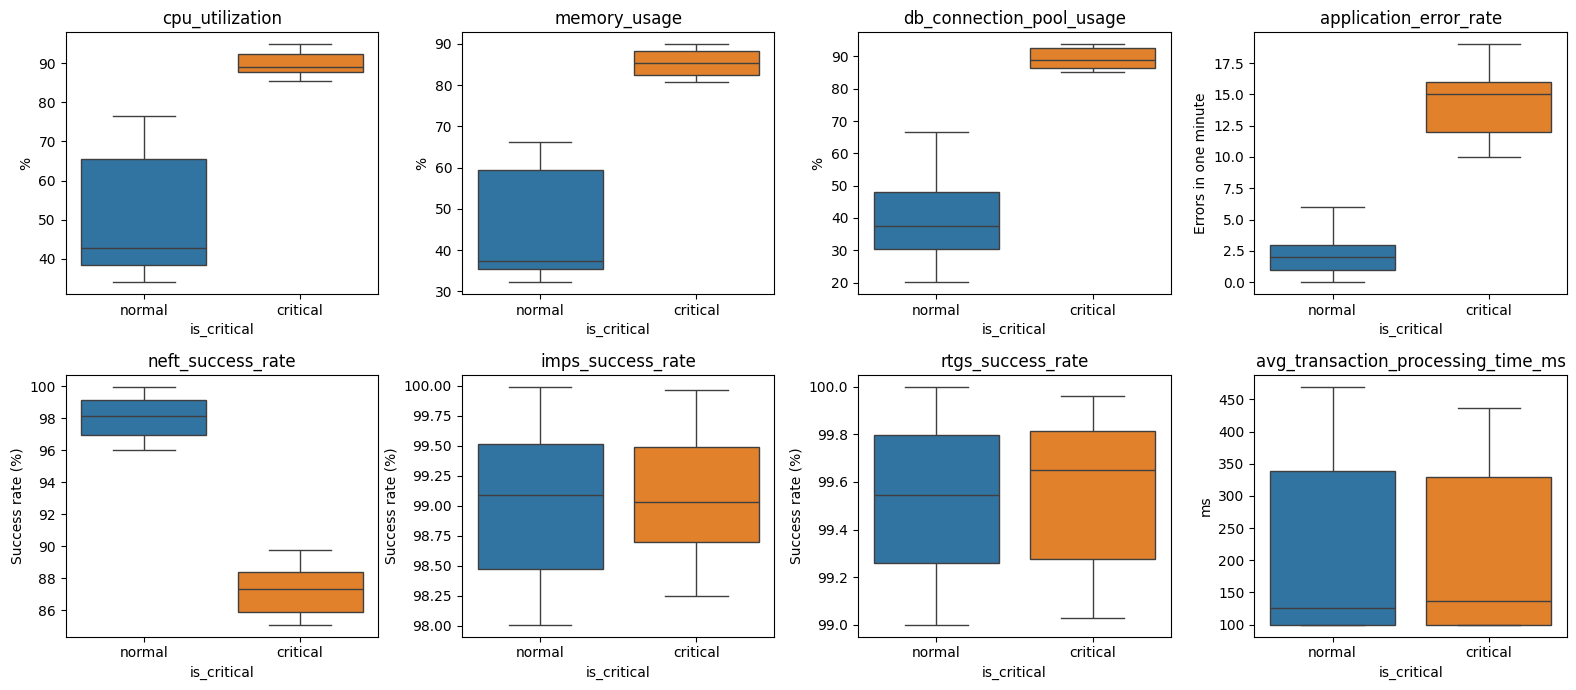

In [66]:
ylabels = {
    'cpu_utilization': '%',
    'memory_usage': '%',
    'db_connection_pool_usage': '%',
    'application_error_rate': 'Errors in one minute',
    'neft_success_rate': 'Success rate (%)',
    'imps_success_rate': 'Success rate (%)',
    'rtgs_success_rate': 'Success rate (%)',
    'avg_transaction_processing_time_ms': 'ms',
}

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(data=ir, x='is_critical', y=col, hue='is_critical', legend=False, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['normal', 'critical'])
    ax.set_title(col)
    ax.set_ylabel(ylabels[col])
fig.tight_layout()

By separating critical incidents from non-critical ones, and plotting the box plots for each of these metrics, we can see several things about critical incidents:

- CPU utilization jumps to at least 85.4%
- Memory usage is at least 80.8%
- DB connection pool usage is at least 85.1%
- Application error rates jump to 10-19
- NEFT success rate drops to a maximum of only 89.8%
- IMPS and RTGS success rates stay the same
- Average transaction processing times mostly stay the same

This shows that when CPU utilization is above 85%, key business KPIs like success and error rates suffer.

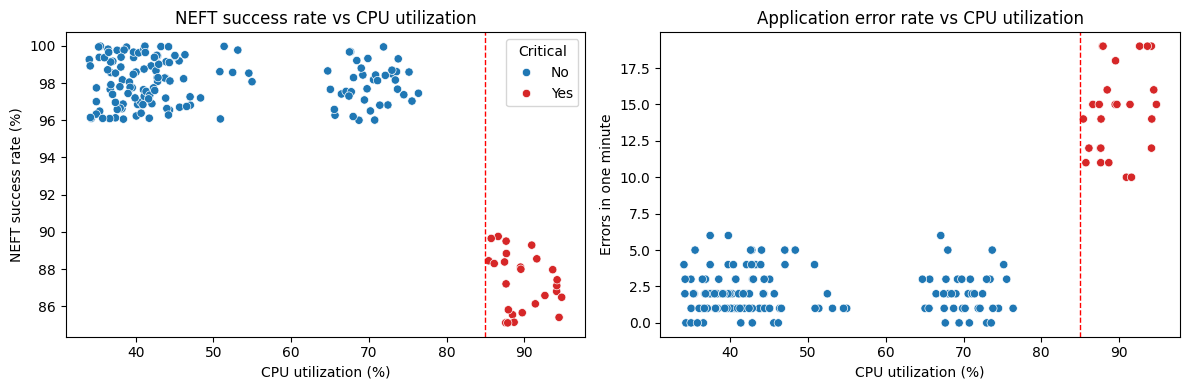

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ir_plot = ir.assign(critical=ir.is_critical.map({0: 'No', 1: 'Yes'}))
pal = {'No': 'C0', 'Yes': 'C3'}

# NEFT success rate vs CPU utilization
sns.scatterplot(
    data=ir_plot, 
    x='cpu_utilization', y='neft_success_rate', 
    hue='critical', hue_order=['No', 'Yes'], 
    palette=pal, ax=axes[0]
)
axes[0].axvline(85, linestyle='--', color='red', linewidth=1)
axes[0].set_title('NEFT success rate vs CPU utilization')
axes[0].set_xlabel('CPU utilization (%)')
axes[0].set_ylabel('NEFT success rate (%)')
axes[0].legend(title='Critical')

# Application error rate vs CPU utilization
sns.scatterplot(
    data=ir_plot, 
    x='cpu_utilization', y='application_error_rate', 
    hue='critical', legend=False,
    palette=pal, ax=axes[1]
)
axes[1].axvline(85, linestyle='--', color='red', linewidth=1)
axes[1].set_title('Application error rate vs CPU utilization')
axes[1].set_xlabel('CPU utilization (%)')
axes[1].set_ylabel('Errors in one minute')

fig.tight_layout()

These two plots show that when CPU is above 85%, NEFT success rate goes down and Application error rates go up. Therefore, the bank should take action whenever CPU is above 85% or predicts that it will to maintain good KPIs.

It is worth noting that this table is similar to the `infrastructure_metrics` table, but 26 timestamps have been replaced with critical incidents and spiked metrics, despite having the same timestamp.


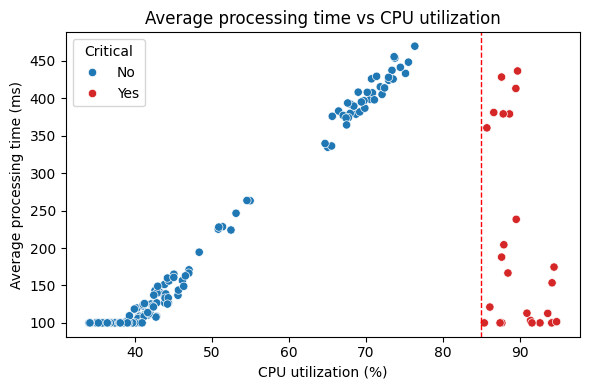

In [68]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(
    data=ir.assign(critical=ir.is_critical.map({0: 'No', 1: 'Yes'})),
    x='cpu_utilization', y='avg_transaction_processing_time_ms',
    hue='critical', hue_order=['No', 'Yes'], palette={'No': 'C0', 'Yes': 'C3'}, ax=ax,
)
ax.axvline(85, linestyle='--', color='red', linewidth=1)
ax.set_title('Average processing time vs CPU utilization')
ax.set_xlabel('CPU utilization (%)')
ax.set_ylabel('Average processing time (ms)')
ax.legend(title='Critical')
fig.tight_layout()

This shows a counterintuitive relationship. Once CPU utilization passes 85%, average processing times have a lower average. This only happens in the `incident_reports` table and not in the `infrastructure_metrics` table.

46% of critical incidents occur between 9 AM and 6 PM


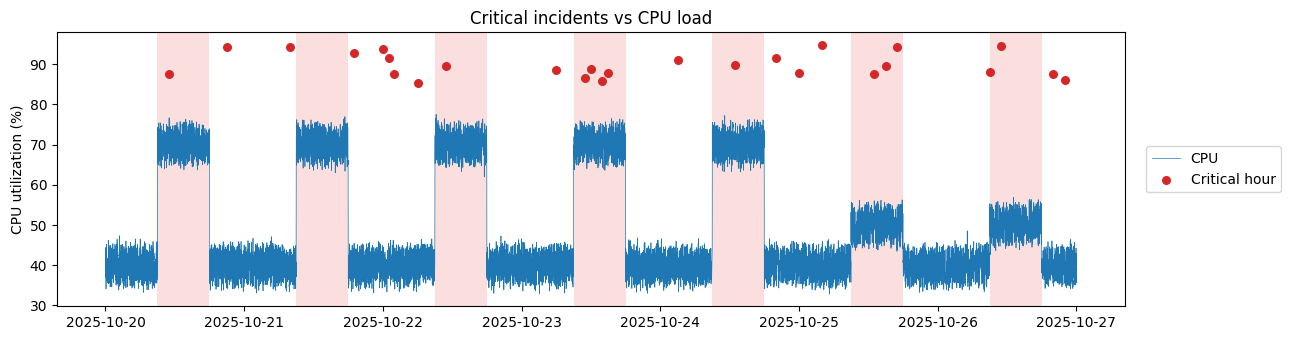

In [69]:
fig, ax = plt.subplots(figsize=(13, 3.5))
for day in im.timestamp.dt.normalize().unique():
    ax.axvspan(day + pd.Timedelta(hours=9), day + pd.Timedelta(hours=18),
               color='lightcoral', alpha=0.25, lw=0)
critical_hours = ir[ir.is_critical == 1]
in_business_hours = critical_hours.timestamp.dt.hour.between(9, 17)
print(f'{100 * in_business_hours.mean():.0f}% of critical incidents occur between 9 AM and 6 PM')

ax.plot(im.timestamp, im.cpu_utilization, lw=0.5, label='CPU')
ax.scatter(critical_hours.timestamp, critical_hours.cpu_utilization,
           color='C3', s=30, zorder=3, label='Critical hour')
ax.set_ylabel('CPU utilization (%)')
ax.set_title('Critical incidents vs CPU load')
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), borderaxespad=0)
fig.tight_layout()

The red dots show when critical incidents occurred during the 7 day period of the dataset. 46% occurred during the business hours of 9am to 6pm. Since 9am to 6pm is 9 hours, which is 37.5% of the day, it shows that critical incidents are slightly more likely during those hours, likely due to the increased load. 

Note that the red dots don't sit on top of the lines. This is because the critical incident points from `incident_reports` table are different from their equivalent points in `infrastructure_metrics` table, likely due to it either measuring another server, or randomly generated synthetic data.

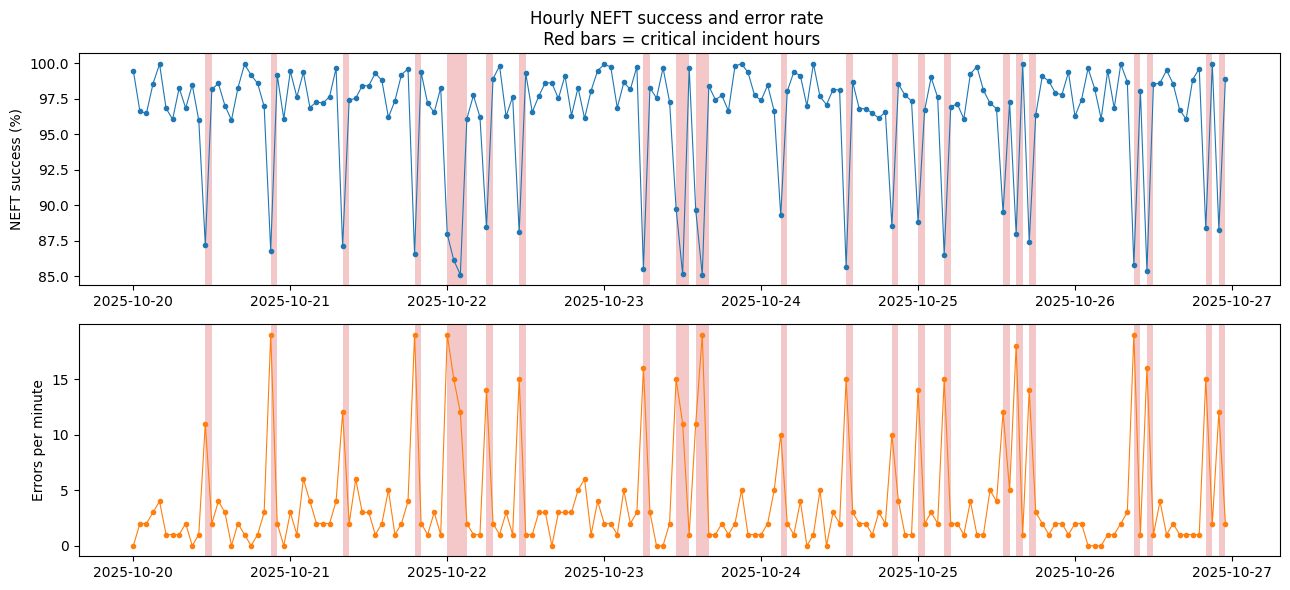

In [70]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6))

axes[0].plot(ir.timestamp, ir.neft_success_rate, marker='.', linewidth=0.8)
axes[0].set_ylabel('NEFT success (%)')

axes[1].plot(ir.timestamp, ir.application_error_rate, marker='.', linewidth=0.8, color='C1')
axes[1].set_ylabel('Errors per minute')

for ax in axes:
    for t in ir.loc[ir.is_critical == 1, 'timestamp']:
        ax.axvspan(t, t + pd.Timedelta(hours=1), color='C3', alpha=0.25, linewidth=0)
        
axes[0].set_title('Hourly NEFT success and error rate \n Red bars = critical incident hours')
fig.tight_layout()

These plots show that during hours where there was a critical incident, success rates drop and error rates spike significantly.

##### Fraud patterns

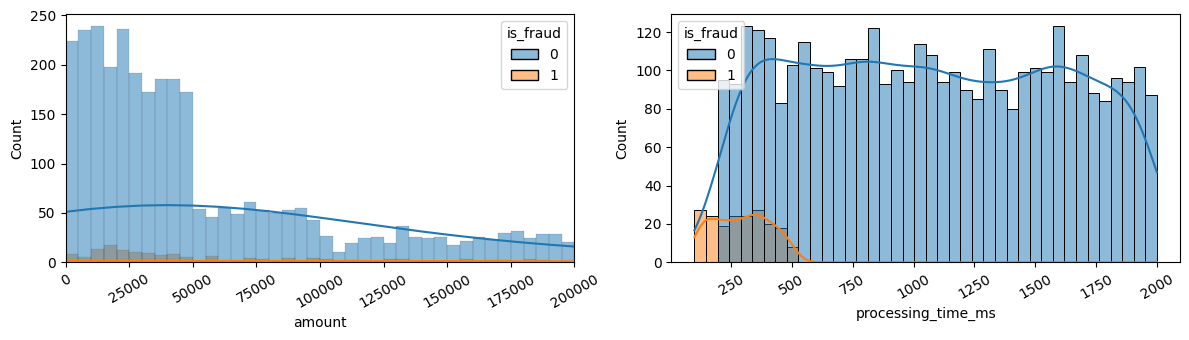

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

# Amount plot
sns.histplot(
    ax=axes[0], data=tf, x='amount', hue='is_fraud',
    bins=40, kde=True, binrange=(0, 200_000)
)
axes[0].set_xlim(0, 200_000)
axes[0].tick_params(axis='x', rotation=30)

# Processing times plot
sns.histplot(
    ax=axes[1], data=tf, x='processing_time_ms', hue='is_fraud',
    bins=40, kde=True
)
axes[1].tick_params(axis='x', rotation=30)

fig.tight_layout()

In [72]:
# Find processing time thresholds that signify fraud
min_time_non_fraud = tf.loc[tf.is_fraud == 0, 'processing_time_ms'].min()
max_time_fraud = tf.loc[tf.is_fraud == 1, 'processing_time_ms'].max()

print('Minimum processing time of regular transactions:', min_time_non_fraud, 'ms')
print('Maximum processing time of fraud transactions:', max_time_fraud, 'ms')

Minimum processing time of regular transactions: 200.24 ms
Maximum processing time of fraud transactions: 498.96 ms


Amount does not reveal any pattern between fraud and regular transactions. 

However, processing times show that fraudulent transactions have lower processing times on average. According to this dataset, a processing time less than 200.24 ms is very likely fraud, and a processing time greater than 498.96 ms is very unlikely to be fraud.


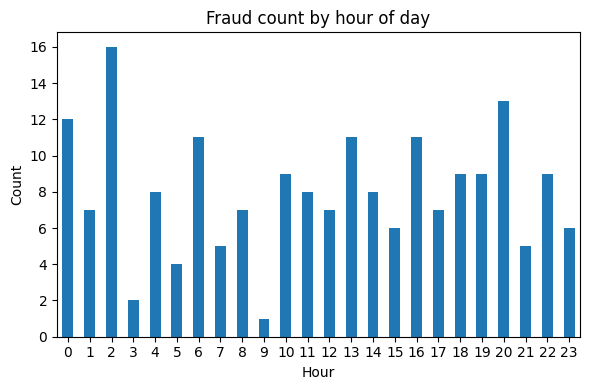

In [73]:
plt.figure(figsize=(6,4))
(
    tf.loc[tf.is_fraud == 1, 'timestamp']
      .dt.hour
      .value_counts()
      .reindex(range(24), fill_value=0)
      .plot.bar(title='Fraud count by hour of day', xlabel='Hour', ylabel='Count')
)
plt.xticks(rotation=0)
plt.tight_layout()


This hourly chart shows some patterns like a lot of fraud occurring between 12 and 2 am, and a somewhat even distribution of fraud during daytime hours until the end of the day.

In [74]:
tf.loc[tf.is_fraud == 1, 'customer_id'].value_counts().head()

customer_id
CUST003582    2
CUST002681    2
CUST004802    2
CUST000260    1
CUST003095    1
Name: count, dtype: int64[pyarrow]

Only 3 customers had two fraudulent transactions.

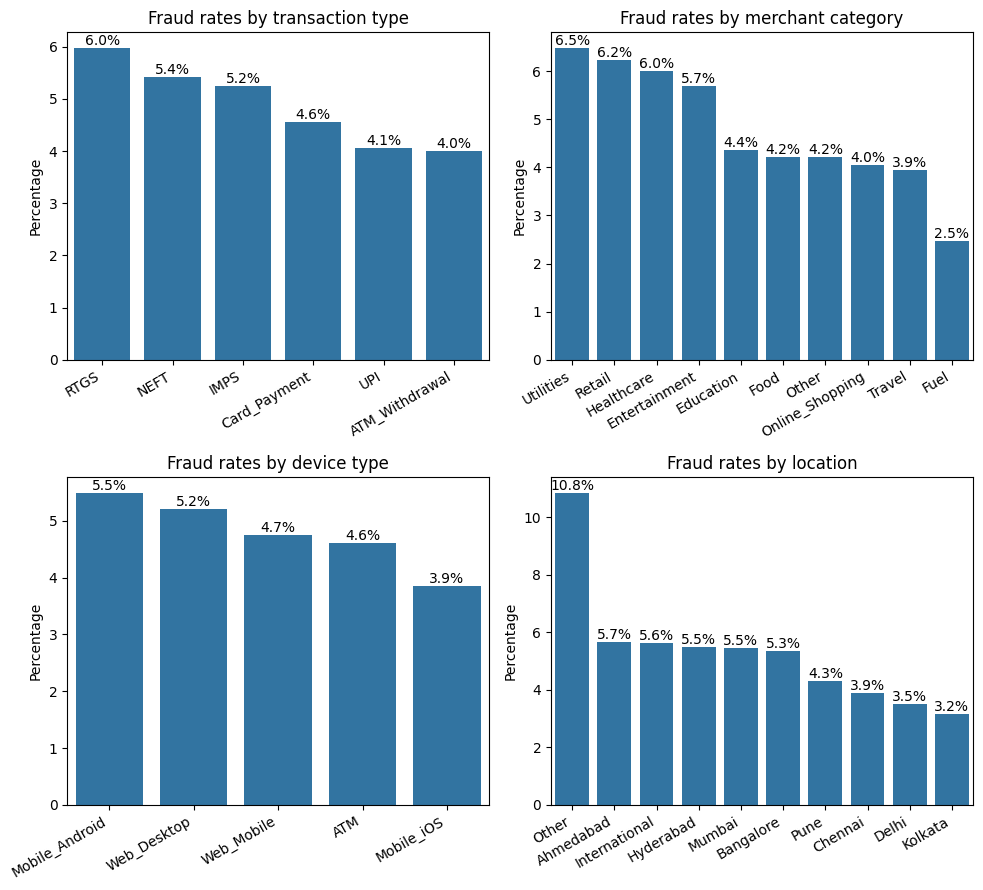

In [75]:
cols = ['transaction_type', 'merchant_category', 'device_type', 'location']
fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for ax, col in zip(axes.flat, cols):
    order = tf.groupby(col, observed=True)['is_fraud'].mean().sort_values(ascending=False).index
    sns.barplot(data=tf.assign(pct=tf.is_fraud * 100), x=col, y='pct', ax=ax, errorbar=None, order=order)
    ax.bar_label(ax.containers[0], fmt='{:.1f}%')
    ax.set_title(f"Fraud rates by {col.replace('_', ' ')}")
    ax.set_xlabel('')
    ax.set_ylabel('Percentage')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    
fig.tight_layout()

Fraud rates are similar between all categories for categorical columns, with some standing out, such as `Other` location having significantly higher fraud rates, and `Fuel` transactions having lower fraud rates. This could either be a consistent pattern for each category, or could be noise that can change depending on the dataset. A chi-square test would give insight into how consistent these rates are. None of these categories seem like strong predictors of fraud.